=== A CORRER O GRID SEARCH ===
Fitting 4 folds for each of 135 candidates, totalling 540 fits


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warn


=== MELHORES HIPERPARÂMETROS ENCONTRADOS ===
{'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 500}
Melhor MAE (negativo) na validação: -1.3928

=== TESTE FINAL COM O MODELO OTIMIZADO ===
MAE: 0.1414
R²: 0.9875

=== MODELO GUARDADO COM SUCESSO EM: model/best_random_forest_model.pkl ===


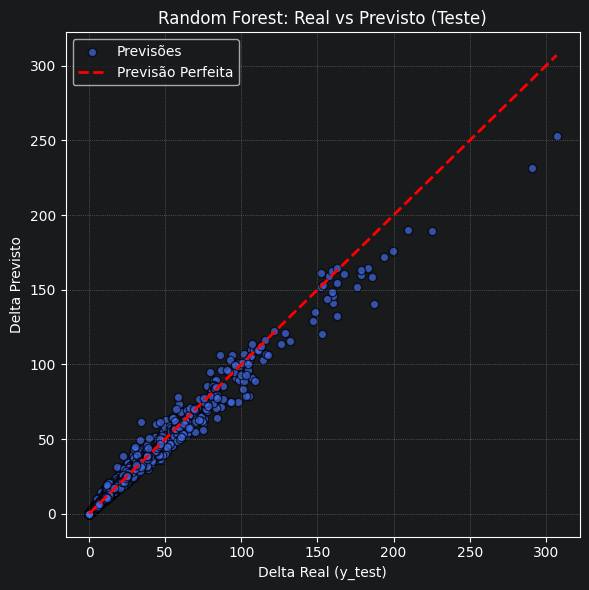

In [3]:
import pandas as pd
import numpy as np

from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, r2_score
from matplotlib import pyplot as plt
import joblib

# 1. Carregar os dados
train_data = pd.read_csv('dataset_area/final.csv')
test_data = pd.read_csv('dataset_area/final_test.csv')

target = 'Delta_area'
group_col = 'AnomalyID'

# Ordenar por data (essencial para o TimeSeriesSplit)
train_data['data'] = pd.to_datetime(train_data['data'])
test_data['data'] = pd.to_datetime(test_data['data'])

train_data = train_data.sort_values(by='data').reset_index(drop=True)

cat_features = ['AnomalyID', 'FacadeRoofID', 'AnomalyType', 'Figura_name']
date_cols = ['data', 'valid_time_']

# Processamento de datas
for df in [train_data, test_data]:
    for col in date_cols:
        df[col] = pd.to_datetime(df[col])
        df[f'{col}_year'] = df[col].dt.year
        df[f'{col}_month'] = df[col].dt.month
    df.drop(columns=date_cols, inplace=True)

# Separar X e y
X_train_full = train_data.drop(columns=[target])
y_train_full = train_data[target]

X_test = test_data.drop(columns=[target])
y_test = test_data[target]

# 2. Definir o pré-processamento e o Pipeline do Random Forest
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OrdinalEncoder(
            handle_unknown='use_encoded_value',
            unknown_value=-1
        ), cat_features)
    ],
    remainder='passthrough'
)

rf_model = RandomForestRegressor(random_state=42, n_jobs=-1)

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', rf_model)
])

# Definir o TimeSeriesSplit
gkf = TimeSeriesSplit(n_splits=4)

# 3. Definir a grelha de hiperparâmetros
param_grid = {
    'model__n_estimators': [100, 300, 500],
    'model__max_depth': [4, 6, 8, 10, None],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4]
}

# 4. Configurar o GridSearchCV
grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=gkf,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    verbose=1
)

print("=== A CORRER O GRID SEARCH ===")
grid_search.fit(X_train_full, y_train_full)

# 5. Ver os melhores resultados
print("\n=== MELHORES HIPERPARÂMETROS ENCONTRADOS ===")
print(grid_search.best_params_)
print(f"Melhor MAE (negativo) na validação: {grid_search.best_score_:.4f}")

# 6. Testar no conjunto de teste final com o melhor modelo
best_rf_model = grid_search.best_estimator_

test_preds_grid = best_rf_model.predict(X_test)
test_preds_grid = np.clip(test_preds_grid, 0, None)

test_mae_grid = mean_absolute_error(y_test, test_preds_grid)
test_r2_grid = r2_score(y_test, test_preds_grid)

print('\n=== TESTE FINAL COM O MODELO OTIMIZADO ===')
print(f'MAE: {test_mae_grid:.4f}')
print(f'R²: {test_r2_grid:.4f}')

# 7. Guardar o modelo otimizado
model_filename = 'model/best_random_forest_model.pkl'
joblib.dump(best_rf_model, model_filename)
print(f"\n=== MODELO GUARDADO COM SUCESSO EM: {model_filename} ===")

# ==========================================
# 8. PLOT DOS RESULTADOS (Real vs Previsto)
# ==========================================
plt.figure(figsize=(6, 6))
plt.scatter(y_test, test_preds_grid, color='royalblue', alpha=0.7, edgecolors='k', label='Previsões')
plt.xlabel("Delta Real (y_test)")
plt.ylabel("Delta Previsto")
plt.title("Random Forest: Real vs Previsto (Teste)")

# Desenhar a linha diagonal de perfeição (y = x)
min_val = min(y_test.min(), test_preds_grid.min())
max_val = max(y_test.max(), test_preds_grid.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Previsão Perfeita')

plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()